In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
#sklearn preprocesin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
#regressor model
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor, VotingRegressor, StackingRegressor
#metrices
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv('/content/sample_data/laptop_dataset.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,brand,name,price,spec_rating,processor,CPU,Ram,Ram_type,ROM,ROM_type,GPU,display_size,resolution_width,resolution_height,OS,warranty
0,0,0,HP,Victus 15-fb0157AX Gaming Laptop,49900,73.000000,5th Gen AMD Ryzen 5 5600H,"Hexa Core, 12 Threads",8GB,DDR4,512GB,SSD,4GB AMD Radeon RX 6500M,15.6,1920.0,1080.0,Windows 11 OS,1
1,1,1,HP,15s-fq5007TU Laptop,39900,60.000000,12th Gen Intel Core i3 1215U,"Hexa Core (2P + 4E), 8 Threads",8GB,DDR4,512GB,SSD,Intel UHD Graphics,15.6,1920.0,1080.0,Windows 11 OS,1
2,2,2,Acer,One 14 Z8-415 Laptop,26990,69.323529,11th Gen Intel Core i3 1115G4,"Dual Core, 4 Threads",8GB,DDR4,512GB,SSD,Intel Iris Xe Graphics,14.0,1920.0,1080.0,Windows 11 OS,1
3,3,3,Lenovo,Yoga Slim 6 14IAP8 82WU0095IN Laptop,59729,66.000000,12th Gen Intel Core i5 1240P,"12 Cores (4P + 8E), 16 Threads",16GB,LPDDR5,512GB,SSD,Intel Integrated Iris Xe,14.0,2240.0,1400.0,Windows 11 OS,1
4,4,4,Apple,MacBook Air 2020 MGND3HN Laptop,69990,69.323529,Apple M1,Octa Core (4P + 4E),8GB,DDR4,256GB,SSD,Apple M1 Integrated Graphics,13.3,2560.0,1600.0,Mac OS,1


In [ ]:
# !pip install ydata-profiling

In [ ]:
# from ydata_profiling import ProfileReport
# profile=ProfileReport(df, title='Laptop Proce Prediction',explorative=True)
# profile.to_file('ydata.html')

In [ ]:
len(df)

893

In [ ]:
len(df.columns)

18

In [ ]:
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'brand', 'name', 'price', 'spec_rating',
       'processor', 'CPU', 'Ram', 'Ram_type', 'ROM', 'ROM_type', 'GPU',
       'display_size', 'resolution_width', 'resolution_height', 'OS',
       'warranty'],
      dtype='object')

In [ ]:
df.nunique()

,0
Unnamed: 0.1,893
Unnamed: 0,893
brand,30
name,815
price,464
spec_rating,30
processor,184
CPU,29
Ram,7
Ram_type,12


In [ ]:
# df.drop( columns = ['Unnamed: 0.1','Unnamed: 0','name'], inplace=True )


In [ ]:
df.drop( columns = ['Unnamed: 0.1','Unnamed: 0'], inplace=True )

In [ ]:
X = df.drop('price',axis=1)
y = df['price']

In [ ]:
numeric_features = X.select_dtypes(include = ['int64','float64']).columns
categorical_features = X.select_dtypes(include = ['object']).columns

In [ ]:
numeric_features

Index(['spec_rating', 'display_size', 'resolution_width', 'resolution_height',
       'warranty'],
      dtype='object')

In [ ]:
categorical_features

Index(['brand', 'name', 'processor', 'CPU', 'Ram', 'Ram_type', 'ROM',
       'ROM_type', 'GPU', 'OS'],
      dtype='object')

In [ ]:
df.nunique()

,0
brand,30
name,815
price,464
spec_rating,30
processor,184
CPU,29
Ram,7
Ram_type,12
ROM,7
ROM_type,2


In [ ]:
len(df.columns)

16

In [ ]:
df.columns

Index(['brand', 'name', 'price', 'spec_rating', 'processor', 'CPU', 'Ram',
       'Ram_type', 'ROM', 'ROM_type', 'GPU', 'display_size',
       'resolution_width', 'resolution_height', 'OS', 'warranty'],
      dtype='object')

In [ ]:
corr_target = df.select_dtypes(include=np.number).corr()['price'].sort_values(ascending=False)
print(corr_target)

price                1.000000
resolution_height    0.604748
resolution_width     0.586042
spec_rating          0.546391
display_size         0.233815
warranty             0.117101
Name: price, dtype: float64


In [ ]:
#pipeline for numeric
num_transform=Pipeline(
    steps=[
        ('imputer',SimpleImputer(strategy='median')),
        ('scaler',StandardScaler())
    ]
)
#pipeline for categorical
cat_transform=Pipeline(
    steps=[
        ('importer',SimpleImputer(strategy='most_frequent')),
        ('encode',OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [ ]:
#combine them
preprocessor = ColumnTransformer(
    transformers= [
        ('num',num_transform,numeric_features),
        ('cat',cat_transform,categorical_features)
    ]
    )

In [ ]:
#split train test
X_train,X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2 , random_state=42)

In [ ]:
#base learner
reg_lr=LinearRegression()
reg_rf=RandomForestRegressor(n_estimators=100, random_state=42)
reg_gb=GradientBoostingRegressor(n_estimators=100, random_state=42)

In [ ]:
#voting regressor
voting_reg=VotingRegressor(
    estimators=[
        ('lr',reg_lr),
        ('rf',reg_rf),
        ('gb',reg_gb)
    ]
)

In [ ]:
#stacking
stacking_reg=StackingRegressor(
    estimators=[
        ('rf',reg_rf),
        ('gb',reg_gb)
    ],
    final_estimator=Ridge()
)

In [ ]:
#all model dictinary create
model_to_train = {
    'Linear Regression' : reg_lr,
    'Random Forest' : reg_rf,
    'Gradient Boosting': reg_gb,
    'Voting Ensemble ' : voting_reg,
    'Stacking Ensemble ' : stacking_reg

}

In [ ]:
#training & Evaluation
results=[]
for name,model in model_to_train.items():
  pipe=Pipeline([
      ('preprocessor',preprocessor),
      ('model',model)
  ])

  #fit
  pipe.fit(X_train,y_train)
  #pred
  y_pred=pipe.predict(X_test)
  #Evaluate
  r2 = r2_score(y_test,y_pred)
  rmse = np.sqrt(mean_squared_error(y_test,y_pred))
  mae = mean_absolute_error(y_test,y_pred)


  results.append({
      "Model": name,
      "R2 Score" :r2,
      "RMSE": rmse,
      "MAE" : mae
  })
results_df = pd.DataFrame(results).sort_values("R2 Score", ascending=False)
print(results_df)

                Model  R2 Score          RMSE           MAE
0   Linear Regression  0.854830  22303.511962  14177.329372
3    Voting Ensemble   0.844943  23050.494242  12653.694890
4  Stacking Ensemble   0.820246  24818.415693  13955.990326
1       Random Forest  0.816059  25105.764002  13331.777786
2   Gradient Boosting  0.799259  26227.246911  15236.329036


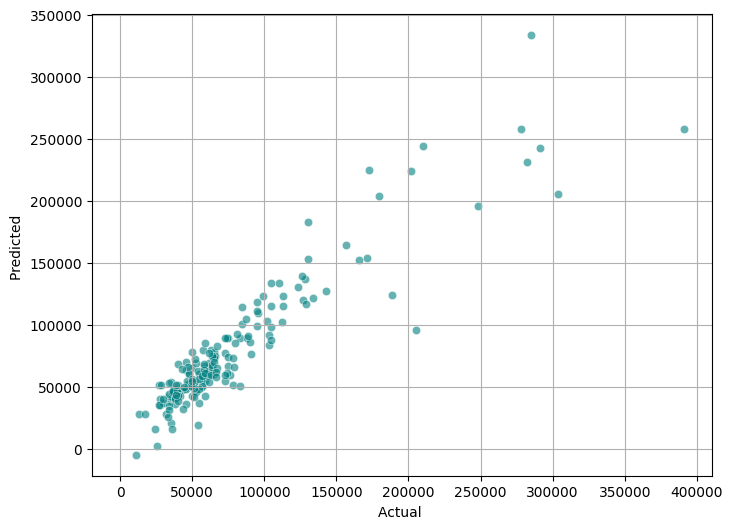

In [ ]:
#visualization
best_model_name=results_df.iloc[0]['Model']
best_model_obj=model_to_train[best_model_name]


#fit the best model
#fit the best model

final_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model',best_model_obj)
])

final_pipe.fit(X_train,y_train)
y_final_pred = final_pipe.predict(X_test)


#plot Actual vs predicted

plt.figure( figsize = (8,6) )

sns.scatterplot(x=y_test, y=y_final_pred, alpha = 0.6, color='teal' )
plt.plot( [2,5] , [2,5], color = "red", linestyle = '--'  )

plt.xlabel("Actual ")
plt.ylabel("Predicted ")

plt.grid(True)
plt.show()

#cross validation

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
rf_pipeline=Pipeline(
    [
     ('preprocessor',preprocessor),
    ('model',RandomForestRegressor(n_estimators=100,random_state=42))
    ]
)


In [ ]:
cv_score=cross_val_score(rf_pipeline, X_train,y_train, cv=5, scoring='neg_mean_squared_error')

In [ ]:
rmse=np.sqrt(-cv_score)
print(rmse)

[38340.71064619 27817.41049905 26720.27009716 36892.81126869
 35695.15914831]


In [ ]:
print(rmse.mean())

33093.272331881235


gridsearchcv

In [ ]:
rf_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('model',RandomForestRegressor(n_estimators=100,random_state=42))
])

In [ ]:
param_grid={
    'model__n_estimators':[100,200],
    'model__max_depth':[None, 10,20],
    'model__min_samples_split':[2,5]
}

In [ ]:
from sklearn.model_selection import GridSearchCV
grid_search=GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

In [ ]:
grid_search.fit(X_train,y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['spec_rating', 'display_size', 'resolution_width', 'resolution_height',
       'warranty'],
      dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('importer',
                                                                                          SimpleImputer(strateg...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         Index(['brand', 'name', 'processor', 'CPU', 'Ram', 'Ram_type', 'ROM',
       'ROM_type', 'GPU', 'OS'],
      dtype='object'))])),
                                       ('model',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 10, 20],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(-grid_search.best_score_)

32751.687785583013


In [ ]:
print(grid_search.best_params_)

{'model__max_depth': 20, 'model__min_samples_split': 2, 'model__n_estimators': 200}


#save

In [40]:
import pickle

filename='model.pkl'
with open(filename,'wb') as file:
  pickle.dump(grid_search,file)

In [41]:
with open('/content/model.pkl','rb') as file:
  loaded_rf=pickle.load(file)

In [44]:
loaded_rf.predict(X_test)

array([ 89379.92849772,  69922.93040061,  73229.70961802, 128773.82733333,
        81198.80881855,  70001.74528675,  56318.61073852,  60981.0816503 ,
        80241.53550064,  16970.25      ,  33494.51206678, 314836.425     ,
        62360.41514624,  53811.71666352,  69743.40864654,  34142.57337219,
        97222.92671347,  70001.74528675,  38109.30191806,  18122.26      ,
        36182.89020769,  27073.11916667,  66364.701738  , 122594.87108929,
        52447.22847382, 136239.59333333,  52167.83892437, 196855.08592048,
        83169.73988455,  71662.1176875 ,  62648.17106592, 189313.18873529,
       110784.5525    ,  53187.90879157, 109709.54894444,  72995.77701279,
        67476.97073122,  28303.55673901,  64519.83767162, 233410.82      ,
        70100.29258014,  42246.93919465,  99922.5637699 , 179403.82824074,
        98877.64782617,  68095.7685754 ,  66290.85723111,  36643.99067769,
        66349.91805864,  56881.92835099,  34340.93929963, 227299.165     ,
        85871.89738432,  

In [46]:
!pip install mlflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 37.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 79.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 62.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 41.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [mlflow]


In [49]:
import mlflow
import mlflow.sklearn
import os

In [57]:
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
mlflow.set_tracking_uri("file:///content/mlruns")
mlflow.set_experiment('laptop_price_using_rf')
my_params = {
    'n_estimators' :100,
    'max_depth' :10,
    'random_state' : 42
}

simple_rf_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('model',RandomForestRegressor(**my_params))
])

with mlflow.start_run(run_name='single_rf'):
  mlflow.log_params(my_params)
  mlflow.log_param("model_type","RandomForestRegressor")
  #train
  simple_rf_pipeline.fit(X_train,y_train)
  y_train_pred = simple_rf_pipeline.predict(X_train)
  train_rmse = np.sqrt(mean_squared_error(y_train,y_train_pred))
  #
  mlflow.log_metric("train rmse",train_rmse)
  #test
  y_test_pred = simple_rf_pipeline.predict(X_test)
  test_rmse = np.sqrt(mean_squared_error(y_test,y_test_pred))

  mlflow.log_metric("test_rmse",test_rmse)

2026/11/05 06:38:58 INFO mlflow.tracking.fluent: Experiment with name 'laptop_price_using_rf' does not exist. Creating a new experiment.
